![Portada](portada.png)

# Proyecto Integrador · Fase 1: Planteamiento y adquisición de imágenes

**Desarrollado por:** Sebastián Abad, Daniel Pacheco y Cinthya Ramón

**Dataset:** frutas de 10 clases (banano, manzana, naranja, limón, tomate, aguacate, pera, mora, fresa, papaya) con su estado (fresca, madura, dañada). Se combinan tres fuentes:
- *Grocery Store Dataset* (Klasson et al., 2019): fotos de frutas en supermercado; aporta la **clase** (8 de las 10 frutas).
- *Fruits fresh and rotten for classification* (Kaggle): manzana, banano y naranja frescas y podridas, sobre fondo claro; aporta el **estado**.
- *Fresh and rotten fruits* (`Original Image`, 16 carpetas de 200 fotos): se usan manzana, banano, naranja y fresa frescas y podridas.
- **Dataset propio** en `../data/base/propio/`, con su registro de captura.

Los originales quedan sin tocar (`data/base`); este cuaderno arma `../data/estructurada/` con las fotos limpias y una tabla de etiquetas.

## Parte 1: Planteamiento del problema

**Escenario:** sección de frutas de un supermercado o frutería. Parte de la fruta se daña antes de venderse porque el estado se revisa a simple vista: depende de la experiencia de cada persona, toma tiempo y no deja registro.

| Causa | Consecuencia |
|---|---|
| Revisión manual y sin registro | La fruta madura no se vende a tiempo ni con descuento |
| Fruta suelta sin código ni fecha | No se sabe cuánto tiempo lleva en el estante |
| Lotes de calidad variable | Pérdidas para el comercio y alimento desperdiciado |

| Actor | Interés |
|---|---|
| Comerciante | Reducir pérdidas y decidir qué vender primero |
| Personal | Apoyo para revisar la fruta sin sumar trabajo |
| Clientes | Fruta en buen estado y descuentos oportunos |
| Proveedores | Información de calidad de sus lotes |
| Comunidad | Menos desperdicio de alimentos |

**Requisitos funcionales**, en orden de prioridad (lo que más pesa en la decisión de venta va primero):

| Prioridad | Requisito | Justificación |
|---|---|---|
| Alta | Detectar y segmentar cada fruta en imagen y video | Sin la región de la fruta no hay clase ni estado |
| Alta | Clasificar el tipo de fruta y su estado | Es la información que usa el comerciante |
| Media | Generar la lista con nombre, precio, stock, fecha de ingreso y recomendación | Conecta el resultado con el negocio |
| Media | Marcar para revisión los productos con datos incompletos | Evita decisiones con datos erróneos |

**No funcionales:** funcionar con distinta luz y con frutas parcialmente tapadas; respuesta apta para video (se mide en FPS); tolerar fallos del OCR; no registrar rostros.

**Restricciones:** cámaras de celular, iluminación variable del local, entrenamiento en Google Colab, tiempo de captura limitado a las entregas y permiso del local.

**Métricas de éxito:** Dice ≥ 0,7 en las máscaras; exactitud, precisión y recall del clasificador clásico; mAP comparado entre dos modelos; FPS en video; 100 % de productos incompletos marcados.

## Parte 2: Construcción y análisis del dataset

Se recorren las tres fuentes y cada imagen se etiqueta con su clase y estado a partir del nombre de la carpeta o del archivo.

In [1]:
import cv2, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

FUENTES = {'grocery': Path('../GroceryStoreDataset/dataset'),
           'kaggle': Path('../dataset'),
           'original': Path('../Original Image'),
           'propio': Path('../data/base/propio')}
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)

# palabra en la ruta -> clase del proyecto
CLASES = {'banana': 'banano', 'apple': 'manzana', 'orange': 'naranja', 'lemon': 'limon', 'lime': 'limon',
          'tomato': 'tomate', 'avocado': 'aguacate', 'pear': 'pera', 'blackberr': 'mora',
          'strawberr': 'fresa', 'papaya': 'papaya'}
PROYECTO = ['banano', 'manzana', 'naranja', 'limon', 'tomate', 'aguacate', 'pera', 'mora', 'fresa', 'papaya']
for c in PROYECTO:
    CLASES[c] = c  # el dataset propio ya usa los nombres en español
ESTADOS = {'fresh': 'fresca', 'rotten': 'dañada', 'fresca': 'fresca', 'madura': 'madura', 'dañada': 'dañada', 'danada': 'dañada'}

In [2]:
def etiquetar(ruta):
    texto = str(ruta).lower().replace('pineapple', '')  # evita confundir piña con manzana
    if 'packages' in texto or 'iconic' in texto:  # jugos, empaques e imágenes de catálogo no son fotos de fruta
        return None, None
    clase = next((v for k, v in CLASES.items() if k in texto), None)
    estado = next((v for k, v in ESTADOS.items() if k in texto), None)
    return clase, estado

filas = []
for fuente, carpeta in FUENTES.items():
    for ruta in carpeta.rglob('*'):
        if fuente == 'kaggle' and ruta.relative_to(carpeta).parts[0] == 'dataset':
            continue  # el zip de Kaggle trae una copia idéntica en dataset/dataset
        if ruta.suffix.lower() not in ('.jpg', '.jpeg', '.png'):
            continue
        clase, estado = etiquetar(ruta.relative_to(carpeta))
        if clase:
            ancho, alto = Image.open(ruta).size  # lee solo la cabecera
            filas.append([fuente, clase, estado, ancho, alto, ruta])

df = pd.DataFrame(filas, columns=['fuente', 'clase', 'estado', 'ancho', 'alto', 'ruta'])
print(len(df), 'imágenes de las 10 clases')
df.head()

16791 imágenes de las 10 clases


,fuente,clase,estado,ancho,alto,ruta
0,grocery,aguacate,NaN,348,348,..\GroceryStoreDataset\dataset\test\Fruit\Avoc...
1,grocery,aguacate,NaN,348,348,..\GroceryStoreDataset\dataset\test\Fruit\Avoc...
2,grocery,aguacate,NaN,348,348,..\GroceryStoreDataset\dataset\test\Fruit\Avoc...
3,grocery,aguacate,NaN,348,464,..\GroceryStoreDataset\dataset\test\Fruit\Avoc...
4,grocery,aguacate,NaN,348,348,..\GroceryStoreDataset\dataset\test\Fruit\Avoc...


### Distribución de clases y estados

fuente    grocery  kaggle  original  total
clase                                     
banano         95    4716       400   5211
manzana       576    5031       400   6007
naranja       175    3852       400   4427
limon         154       0         0    154
tomate        235       0         0    235
aguacate       86       0         0     86
pera          229       0         0    229
mora            0       0         0      0
fresa           0       0       400    400
papaya         42       0         0     42
total        1592   13599      1600  16791 

estado    dañada  fresca  sin estado
clase                               
aguacate       0       0          86
banano      2954    2162          95
fresa        200     200           0
limon          0       0         154
manzana     3143    2288         576
naranja     2198    2054         175
papaya         0       0          42
pera           0       0         229
tomate         0       0         235


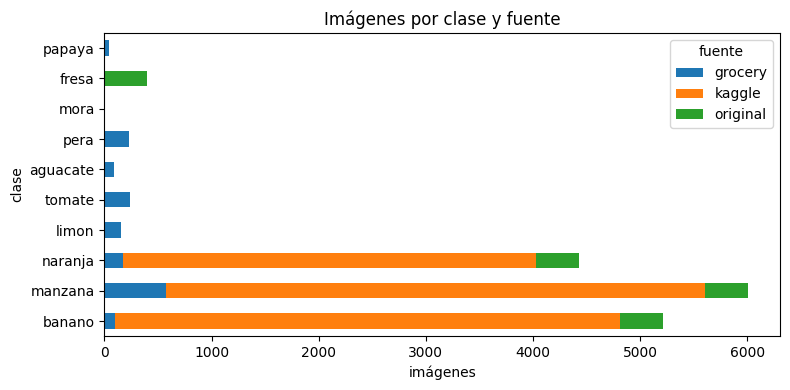

In [3]:
tabla = pd.crosstab(df.clase, df.fuente, margins=True, margins_name='total').reindex(PROYECTO + ['total'], fill_value=0)
print(tabla, '\n')
print(pd.crosstab(df.clase, df.estado.fillna('sin estado')))

tabla.drop('total').drop(columns='total').plot.barh(stacked=True, figsize=(8, 4))
plt.xlabel('imágenes'); plt.title('Imágenes por clase y fuente'); plt.tight_layout()
plt.savefig(FIG / '01_distribucion.png', dpi=200); plt.show()

Grocery Store no trae el estado y los dos datasets de fruta podrida solo cubren cuatro frutas en dos estados: el estado *madura* y la mora dependen del dataset propio.

### Resoluciones

In [4]:
df['megapixeles'] = df.ancho * df.alto / 1e6
df.groupby('fuente')[['ancho', 'alto', 'megapixeles']].agg(['min', 'median', 'max']).round(2)

ancho               alto               megapixeles              
           min  median   max  min  median   max         min median    max
fuente                                                                   
grocery    348   348.0   464  348   348.0   464        0.12   0.12   0.16
kaggle     144   404.0   862  116   364.0   518        0.02   0.15   0.38
original   469  2683.5  4160  446  2469.5  4160        0.21   6.55  12.98

### Ejemplos y verificación de etiquetas

Una imagen al azar por cada combinación de fuente, clase y estado, para revisar a simple vista que la etiqueta coincide con la foto.

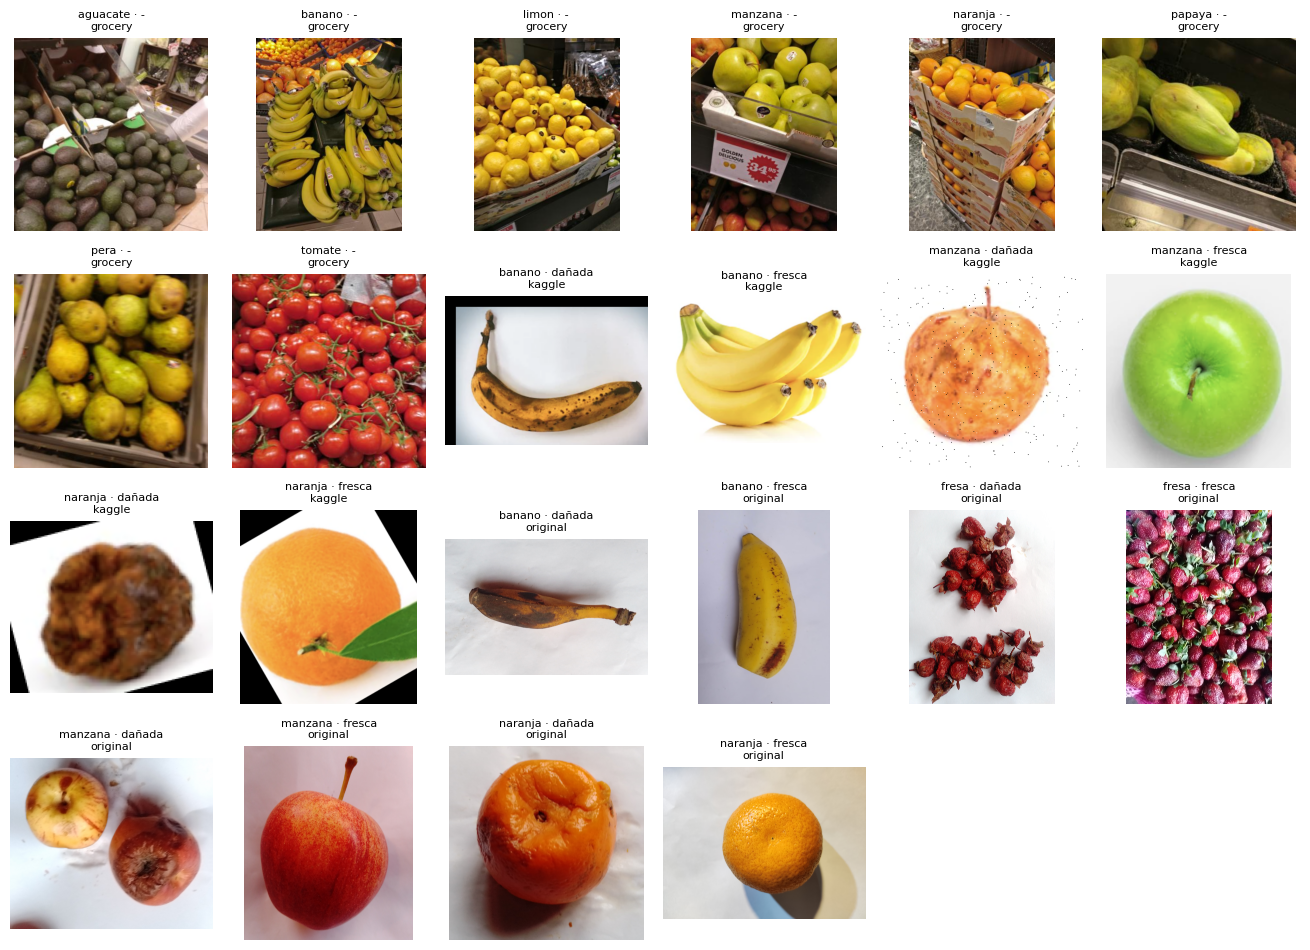

In [5]:
grupos = df.fillna({'estado': '-'}).groupby(['fuente', 'clase', 'estado'])
muestra = grupos.sample(1, random_state=0)
n = len(muestra); cols = 6; rows = int(np.ceil(n / cols))
fig, ax = plt.subplots(rows, cols, figsize=(2.2 * cols, 2.4 * rows))
for a in ax.flat: a.axis('off')
for a, (_, f) in zip(ax.flat, muestra.iterrows()):
    a.imshow(Image.open(f.ruta)); a.set_title(f'{f.clase} · {f.estado}\n{f.fuente}', fontsize=8)
plt.tight_layout(); plt.savefig(FIG / '02_ejemplos.png', dpi=200); plt.show()

In [6]:
# meta mínima: 50 imágenes por clase y estado
conteo = grupos.size()
print('Combinaciones con menos de 50 imágenes:')
print(conteo[conteo < 50])

# formato de nombre del dataset propio: clase_estado_persona_fecha_numero.jpg
propio = df[df.fuente == 'propio']
mal_nombre = propio[~propio.ruta.map(lambda r: r.stem).str.match(r'^[a-zñ]+_[a-zñ]+_[A-Z]_\d{4}-\d{2}-\d{2}_\d{3}$')]
print(f'\nPropio: {len(propio)} fotos, {len(mal_nombre)} con nombre fuera de formato')

Combinaciones con menos de 50 imágenes:
fuente   clase   estado
grocery  papaya  -         42
dtype: int64

Propio: 0 fotos, 0 con nombre fuera de formato


### Condiciones de captura del dataset propio

In [7]:
registro = Path('../data/base/registro_captura.csv')
if registro.exists():
    cap = pd.read_csv(registro)
    display(cap)
    print(cap.groupby(['tipo_luz', 'fondo']).imagenes.sum())
else:
    print('Aún no hay registro de captura')

,fecha,hora,persona,lugar,tipo_luz,dispositivo,fondo,clases,imagenes


Series([], Name: imagenes, dtype: object)


### Limpieza

Se toman hasta 250 fotos al azar por fuente, clase y estado, para equilibrar las clases (Kaggle tiene más de 1.500 por grupo) y porque las máscaras se anotarán a mano. En esa muestra se eliminan duplicados exactos y fotos borrosas; la nitidez es la varianza del Laplaciano, que es alta cuando hay bordes marcados.

In [8]:
def nitidez(ruta):
    gris = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
    gris = cv2.resize(gris, (256, 256))  # misma escala para comparar fotos de distinto tamaño
    return cv2.Laplacian(gris, cv2.CV_64F).var()

df = df.fillna({'estado': '-'}).sample(frac=1, random_state=0).groupby(['fuente', 'clase', 'estado']).head(250)
df['hash'] = df.ruta.map(lambda r: hashlib.md5(r.read_bytes()).hexdigest())
df['nitidez'] = df.ruta.map(nitidez)
# borrosa: menos de 1/5 de la nitidez mediana de su fuente
umbral = df.groupby('fuente').nitidez.transform('median') / 5

duplicada = df.duplicated('hash')
borrosa = df.nitidez < umbral
print(f'Duplicadas: {duplicada.sum()}  Borrosas: {borrosa.sum()}  de {len(df)}')
print(df[duplicada | borrosa].groupby('fuente').size())

Duplicadas: 7  Borrosas: 250  de 4366
fuente
grocery      14
kaggle      216
original     27
dtype: int64


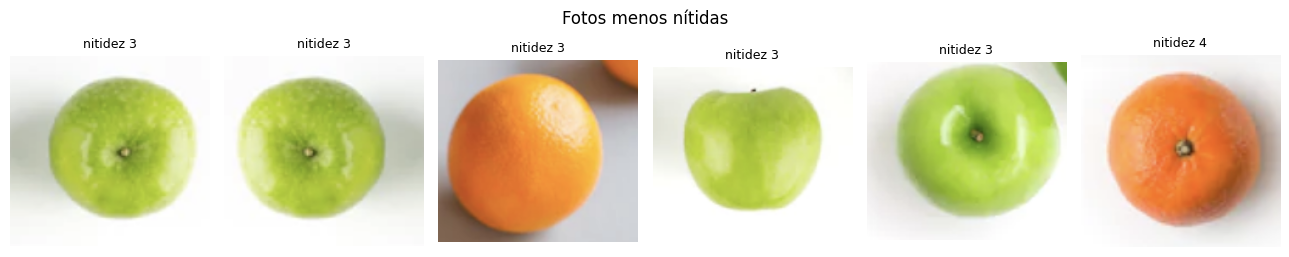

3911 imágenes quedan


In [9]:
peores = df.nsmallest(6, 'nitidez')
fig, ax = plt.subplots(1, 6, figsize=(13, 2.6))
for a, (_, f) in zip(ax, peores.iterrows()):
    a.imshow(Image.open(f.ruta)); a.set_title(f'nitidez {f.nitidez:.0f}', fontsize=9); a.axis('off')
plt.suptitle('Fotos menos nítidas'); plt.tight_layout()
plt.savefig(FIG / '03_borrosas.png', dpi=200); plt.show()

limpio = df[~(duplicada | borrosa)].groupby(['fuente', 'clase', 'estado']).head(200).drop(columns='hash')
print(len(limpio), 'imágenes quedan')

### Dataset estructurado

Cada foto limpia se guarda con lado máximo de 512 px y nombre `clase_estado_fuente_número.jpg`, junto con `etiquetas.csv`. La Fase 2 parte de esta carpeta.

In [10]:
SALIDA = Path('../data/estructurada')
filas = []
for (clase, estado, fuente), g in limpio.groupby(['clase', 'estado', 'fuente']):
    (SALIDA / clase).mkdir(parents=True, exist_ok=True)
    for i, f in enumerate(g.itertuples(), 1):
        img = cv2.imread(str(f.ruta))
        escala = 512 / max(img.shape[:2])
        if escala < 1:
            img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)  # INTER_AREA promedia píxeles al reducir
        nombre = f'{clase}_{estado.replace("-", "sinestado")}_{fuente}_{i:03d}.jpg'
        cv2.imwrite(str(SALIDA / clase / nombre), img)
        filas.append([f'{clase}/{nombre}', clase, estado, fuente, f.ruta.as_posix()])

etiquetas = pd.DataFrame(filas, columns=['archivo', 'clase', 'estado', 'fuente', 'original'])
etiquetas.to_csv(SALIDA / 'etiquetas.csv', index=False)
pd.crosstab(etiquetas.clase, etiquetas.estado, margins=True, margins_name='total')

estado,-,dañada,fresca,total
clase,,,,
aguacate,86,0,0,86
banano,95,400,395,890
fresa,0,200,200,400
limon,151,0,0,151
manzana,200,396,394,990
naranja,172,390,392,954
papaya,40,0,0,40
pera,200,0,0,200
tomate,200,0,0,200


## Parte 3: Representación de la imagen y espacios de color

Una imagen es una matriz de alto × ancho × canales; cada canal usa 8 bits (0 a 255).

In [11]:
ejemplo = limpio[(limpio.clase == 'banano') & (limpio.estado == 'dañada')].iloc[0].ruta
img = cv2.imread(str(ejemplo))  # OpenCV lee en BGR
print('shape (alto, ancho, canales):', img.shape)
print('tipo:', img.dtype, '->', img.itemsize * 8 * img.shape[2], 'bits por píxel')
print(f'memoria: {img.nbytes / 1e6:.2f} MB   disco: {ejemplo.stat().st_size / 1e6:.2f} MB')

shape (alto, ancho, canales): (426, 528, 3)
tipo: uint8 -> 24 bits por píxel
memoria: 0.67 MB   disco: 0.35 MB


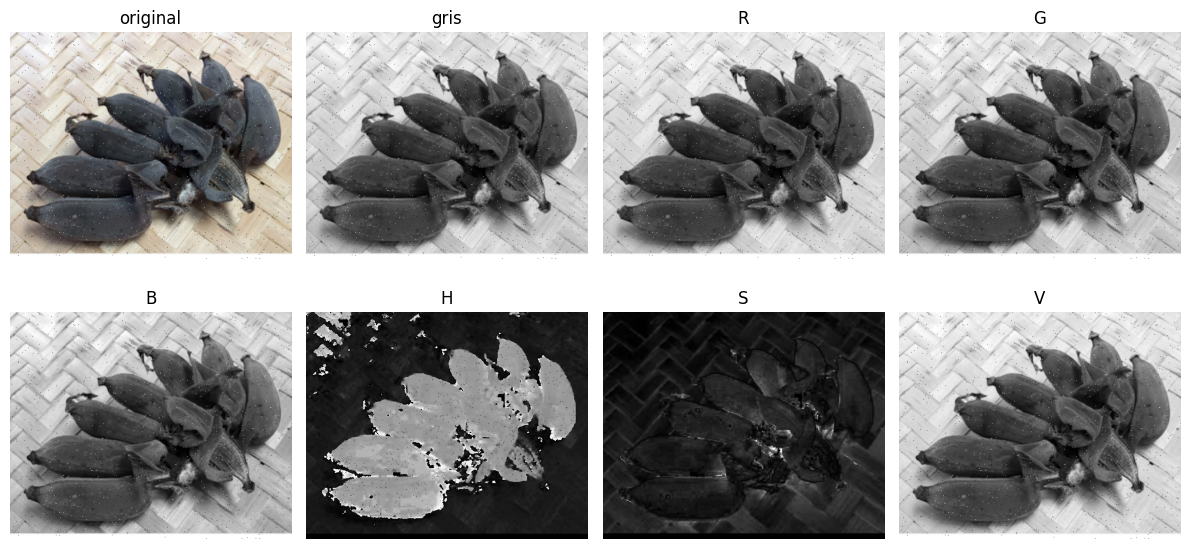

In [12]:
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)  # H va de 0 a 179

paneles = [(rgb, 'original'), (gris, 'gris')] + [(rgb[..., i], c) for i, c in enumerate('RGB')] \
          + [(hsv[..., i], c) for i, c in enumerate('HSV')]
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, (p, t) in zip(ax.flat, paneles):
    a.imshow(p, cmap=None if p.ndim == 3 else 'gray'); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.savefig(FIG / '04_espacios_color.png', dpi=200); plt.show()

### Fresca contra dañada

Para comparar solo la fruta y no el fondo, se crea una máscara con Otsu sobre la saturación (el fondo de estas fotos es claro y poco saturado).

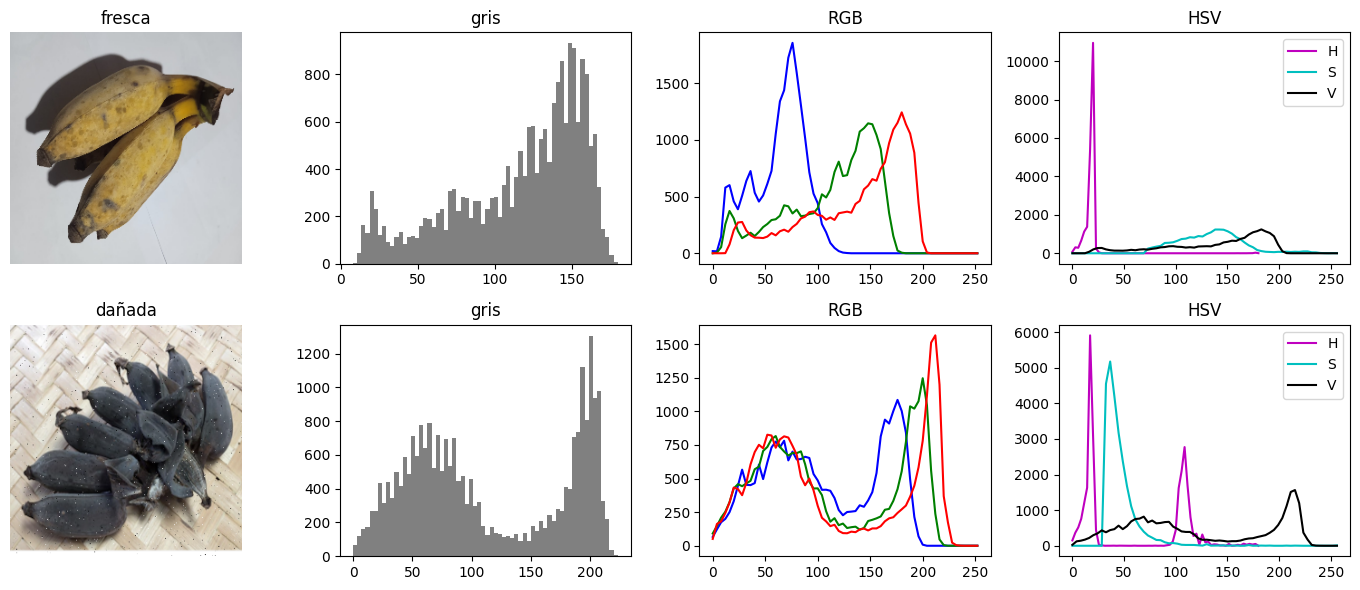

In [13]:
def mascara(img):
    s = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m

pares = [limpio[(limpio.clase == 'banano') & (limpio.estado == e)].iloc[0].ruta for e in ('fresca', 'dañada')]
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for fila, ruta in zip(ax, pares):
    im = cv2.resize(cv2.imread(str(ruta)), (256, 256)); m = mascara(im)
    fila[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); fila[0].axis('off')
    fila[1].hist(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)[m > 0], 64, color='gray'); fila[1].set_title('gris')
    for i, c in enumerate('bgr'):
        fila[2].plot(np.arange(0, 256, 4), cv2.calcHist([im], [i], m, [64], [0, 256]), c); fila[2].set_title('RGB')
    h = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    for i, (c, r) in enumerate(zip(['m', 'c', 'k'], [180, 256, 256])):
        fila[3].plot(np.linspace(0, r, 64), cv2.calcHist([h], [i], m, [64], [0, r]), c, label='HSV'[i])
    fila[3].set_title('HSV'); fila[3].legend()
ax[0, 0].set_title('fresca'); ax[1, 0].set_title('dañada')
plt.tight_layout(); plt.savefig(FIG / '05_histogramas_estado.png', dpi=200); plt.show()

### ¿Qué espacio separa mejor el estado?

Cada fruta se resume con el color medio dentro de su máscara. Se clasifica fresca o dañada por el centroide más cercano (mitad para calcular centroides, mitad para probar).

In [14]:
# hasta 100 fotos al azar por clase y estado
estado = limpio[limpio.estado.isin(['fresca', 'dañada'])].sample(frac=1, random_state=0).groupby(['clase', 'estado']).head(100)

def color_medio(ruta):
    im = cv2.resize(cv2.imread(str(ruta)), (128, 128)); m = mascara(im)
    return {'gris': [cv2.mean(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), m)[0]],
            'RGB': cv2.mean(im, m)[:3],
            'HSV': cv2.mean(cv2.cvtColor(im, cv2.COLOR_BGR2HSV), m)[:3]}

feats = estado.ruta.map(color_medio)
y = estado.estado.values
mitad = np.arange(len(y)) % 2 == 0
resultados = {}
for espacio in ['gris', 'RGB', 'HSV']:
    X = np.array([f[espacio] for f in feats])
    X = (X - X.mean(0)) / X.std(0)  # misma escala en todos los canales
    centros = {e: X[mitad & (y == e)].mean(0) for e in ['fresca', 'dañada']}
    pred = [min(centros, key=lambda e: np.linalg.norm(x - centros[e])) for x in X[~mitad]]
    resultados[espacio] = np.mean(np.array(pred) == y[~mitad])
pd.Series(resultados, name='acierto').mul(100).round(1)

gris    66.8
RGB     66.8
HSV     61.5
Name: acierto, dtype: float64

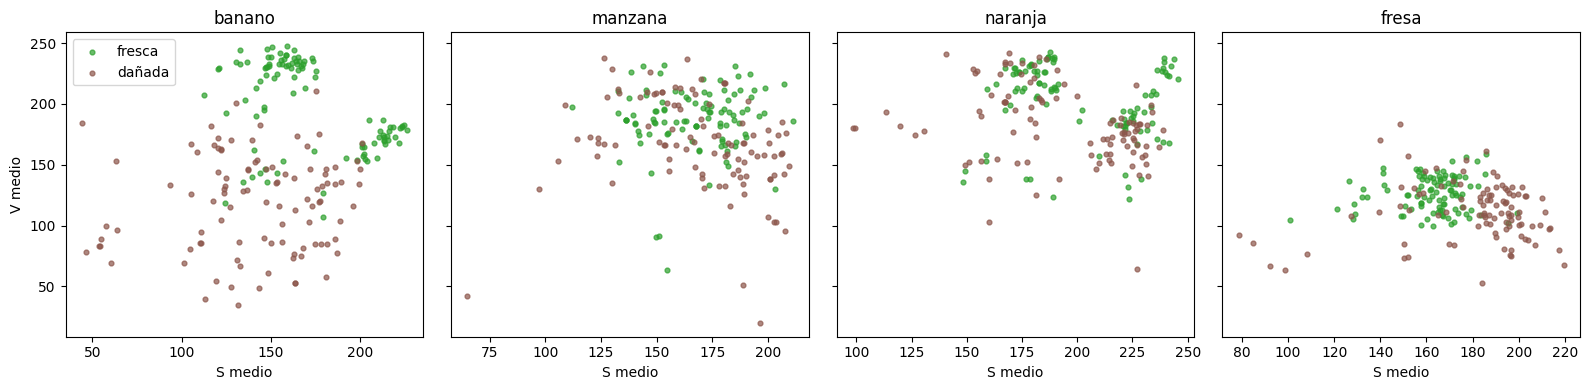

In [15]:
hsv_medio = np.array([f['HSV'] for f in feats])
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for a, clase in zip(ax, ['banano', 'manzana', 'naranja', 'fresa']):
    for e, col in [('fresca', 'tab:green'), ('dañada', 'tab:brown')]:
        sel = (estado.clase.values == clase) & (y == e)
        a.scatter(hsv_medio[sel, 1], hsv_medio[sel, 2], s=12, c=col, label=e, alpha=.7)
    a.set_title(clase); a.set_xlabel('S medio')
ax[0].set_ylabel('V medio'); ax[0].legend()
plt.tight_layout(); plt.savefig(FIG / '06_separacion_hsv.png', dpi=200); plt.show()

## Conclusiones

- Se reunieron **16.791 imágenes** de 9 de las 10 frutas: Grocery Store aporta 8 clases (1.592 fotos, todas sin estado), Kaggle 13.599 y Original Image 1.600 con fruta fresca y dañada. La mora no aparece en ninguna base pública y el estado *madura* tampoco: ambos dependen del dataset propio.
- Las fuentes están muy desbalanceadas (manzana 6.007 fotos, papaya 42) y sus resoluciones van de 0,02 MP (Kaggle) a 13 MP (Original Image). Por eso se tomó una muestra de hasta 250 por grupo y se igualó el tamaño a 512 px.
- La limpieza eliminó 7 duplicados y 250 fotos borrosas, sobre todo de Kaggle (216), cuyas imágenes son capturas ampliadas. Quedan **3.911 imágenes** en `data/estructurada`.
- Separar fresca de dañada con el color medio da 66,8 % en gris y RGB y 61,5 % en HSV. HSV no ganó porque el promedio de H falla en frutas rojas (el matiz da la vuelta entre 0 y 179) y porque el color medio pierde las manchas. En el banano sí se separan bien, porque la fruta dañada baja mucho su brillo V. En la Fase 3 harán falta histogramas completos y textura (LBP) para describir el daño.
